# 02 Kansas ML: Train U-Net Cost Map, Batch-Digitize, and Validate

This notebook implements the complete **ML cost-map + DP curve-tracing** workflow on the paired Kansas Geological Survey (KGS) wells:
1. **Strict well-level split** (`train` vs `holdout`) with zero data leakage between training and evaluation wells.
2. **Training tile generation** from LAS-to-pixel alignment (`ml_training_data.build_training_dataset`, plus `las_to_pixel_labels` and `make_tiles`).
3. **Lightweight 2D U-Net (`CurveUNet`)** with automatic device selection (`mps` on Apple Silicon, `cuda` if available, else `cpu`).
4. **Model training / checkpoint inspection** (`models/kansas_gr_unet.pt` and `models/kansas_kgs/unet.pt`).
5. **Batch digitization (`ml_batch_digitize.digitize_batch`)** on the 4 held-out wells using the **same Rust/Numba DP tracer** on the learned U-Net cost map.
6. **Validation against paired KGS LAS** (comparing Conventional vs ML cost map `r` and `RMSE`) and **low-confidence interval review queue** (`ml_batch_digitize.review_queue`).
7. **Incremental fine-tuning (`ml_training.fine_tune`)** from saved web-editor sessions.

In [1]:
import json, pathlib, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "example_data"
OUT = ROOT / "outputs"
QC = OUT / "qc"
QC.mkdir(parents=True, exist_ok=True)

from pylogdigitizer import (
    curve_tracing as ct,
    dataset_profiles,
    ml_models,
    ml_training_data as mtd,
    ml_training,
    ml_batch_digitize as mbd,
)

print("DP tracer backend:", ct.backend())
print("Selected compute device:", ml_models.select_device())

DP tracer backend: rust
Selected compute device: cpu


## 1. Wells and Dataset Profile
Read `example_data/wells_index.csv` (paired KGS wells) and `dataset_profiles/kansas_kgs.yaml`.

In [2]:
prof = dataset_profiles.load_profile(str(ROOT / "dataset_profiles/kansas_kgs.yaml"))
wells = pd.read_csv(DATA / "wells_index.csv", dtype=str)
paired = wells[wells.paired == "yes"].reset_index(drop=True)
print(f"Profile: {prof['name']} | Paired Kansas wells: {len(paired)}")
paired[["well", "API", "company", "log_date", "las_curves"]]

Profile: kansas_kgs | Paired Kansas wells: 12


,well,API,company,log_date,las_curves
0,USA 'A' 16,15-055-20536,Gearhart,25-Sep-1983,GR NPHI RHOB ILD
1,MOBIL 12-1,15-189-20087,Schlumberger,12-Feb-1970,SP ILD DT POROSITY
2,Chitwood 12,15-151-10469,Schlumberger,11-Nov-1945,SP ILD GR:1 NEUT:1 GR:2 NEUT:2 CALI DT
3,Hall 'D' 4,15-051-05370,Welex,06-Nov-1978,GR NEUT SP ILD
4,Minzer 1,15-077-30177,Halliburton,21-Jun-1955,GR NEUT ILD
5,MAKEMSON 'A' 1,15-081-20018,Dresser Atlas,20-Aug-1969,ILD GR DT
6,ELY 1,15-135-19136,Welex,05-Aug-1963,RES GR DT
7,George B. Strong Unit 8,15-175-20098,Schlumberger,26-Feb-1970,SP ILD RHOB DT
8,Swanson 1,15-117-20008,Great Guns,20-Apr-1978,ILD GR RHOB
9,WEATHERFORD 'B' 1,15-129-20464,Schlumberger,12-Sep-1980,CALI DPHI GR ILD ILM NPHI RHOB SFL SP


## 2. Strict Well-Level Split (Zero Data Leakage)
All tiles from a given well stay exclusively in either `train` or `holdout` — never both.

In [3]:
split = mtd.split_wells()
api_split = mtd.split_by_well(paired.API.tolist(), fractions=(0.6, 0.2, 0.2), seed=42)
assert set(split["train"]).isdisjoint(split["holdout"]), "Data leakage detected!"
print("GR Train wells   (4):", split["train"])
print("GR Holdout wells (4):", split["holdout"])
print("Zero well overlap verified:", len(set(split["train"]) & set(split["holdout"])) == 0)
print("Generic 12-well API split counts:", {k: len(v) for k, v in api_split.items()})

GR Train wells   (4): ['Hall_D_4', 'MAKEMSON_A_1', 'Chitwood_12', 'Minzer_1']
GR Holdout wells (4): ['USA_A_16', 'WEATHERFORD_B_1', 'BACASTOW_1', 'GOHEEN_UNIT_1']
Zero well overlap verified: True
Generic 12-well API split counts: {'train': 7, 'val': 2, 'test': 3}


## 3. Build Training Strip Tiles from Training Wells
For each training well, we align the paired LAS reference curve (`GR`) to the deskewed track panel, snap the reference to the nearest ink stroke within a local search window (`snap_reference_to_ink`), extract the 8-channel domain feature map (`extract_dp_features`), and slice `256 x 96` DP-resolution strip tiles (`build_training_dataset`).

In [4]:
CACHE_NPZ = ROOT / "outputs" / "tiles" / "kansas_gr_dp_records.npz"
records = ml_training.load_records_from_npz(CACHE_NPZ)

ds_train = mtd.build_training_dataset(
    records,
    allowed_wells=split["train"],
    tile_rows=256,
    stride_rows=128,
    width_std=96,
)
ds_holdout = mtd.build_training_dataset(
    records,
    allowed_wells=split["holdout"],
    tile_rows=256,
    stride_rows=256,
    width_std=96,
)

assert set(ds_train["wells"]).isdisjoint(ds_holdout["wells"])
print(f"Train tiles   : X={ds_train['X'].shape}, Y={ds_train['Y'].shape}, W={ds_train['W'].shape}")
print("Train tiles per well  :", pd.Series(ds_train["wells"]).value_counts().to_dict())
print(f"Holdout tiles : X={ds_holdout['X'].shape}, Y={ds_holdout['Y'].shape}, W={ds_holdout['W'].shape}")
print("Holdout tiles per well:", pd.Series(ds_holdout["wells"]).value_counts().to_dict())

Train tiles   : X=(204, 8, 256, 96), Y=(204, 1, 256, 96), W=(204, 1, 256, 96)
Train tiles per well  : {'MAKEMSON_A_1': 91, 'Chitwood_12': 68, 'Minzer_1': 25, 'Hall_D_4': 20}
Holdout tiles : X=(296, 8, 256, 96), Y=(296, 1, 256, 96), W=(296, 1, 256, 96)
Holdout tiles per well: {'USA_A_16': 131, 'BACASTOW_1': 74, 'WEATHERFORD_B_1': 66, 'GOHEEN_UNIT_1': 25}


## 4. U-Net Architecture (`CurveUNet`) and Device Selection
`CurveUNet` is a compact 3-stage 2D U-Net (`in_channels=8, base_channels=16, width_std=96`, ~100k parameters) with residual `1x1` projection from input features so it trains in ~15–20 seconds on CPU (and faster on Apple Silicon `mps` or `cuda`).

The 8 input channels per DP pixel `(row, col)` are:
0. `ir_close`: vertically closed grid-cleaned ink mask
1. `1 - cost_conv`: inverted conventional DP cost
2. `v61`: 61-row (~180 px) vertical persistence (identifies stationary vertical curves like Caliper or bit-size lines)
3. `v21`: 21-row (~63 px) local continuity
4. `dynamic_ink`: `ir_close * (1 - 0.85 * clip((v61 - 0.30) / 0.45, 0, 1))` (highlights active, non-stationary curve strokes)
5. `row_act`: normalized row ink density
6. `x_norm`: normalized horizontal track coordinate `[0, 1]`
7. `ink_cls`: morphological thick-stroke mask

In [5]:
device = ml_models.select_device()
model = ml_models.build_curve_segmenter(in_channels=8, n_classes=1, base_channels=16, width_std=96)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model: {model.__class__.__name__} | Parameters: {n_params:,} | Device: {device}")

Model: CurveUNet | Parameters: 211,793 | Device: cpu


## 5. Train or Load `models/kansas_gr_unet.pt`
If `models/kansas_gr_unet.pt` already exists, we load it and inspect its training history (`models/kansas_kgs/training_history.json`); otherwise we run `ml_training.train` to train it from scratch on the 4 training wells.

Checkpoint loaded: models/kansas_gr_unet.pt
Trained strictly on wells: ['Hall_D_4', 'MAKEMSON_A_1', 'Chitwood_12', 'Minzer_1']
Validated on held-out wells: ['USA_A_16', 'WEATHERFORD_B_1', 'BACASTOW_1', 'GOHEEN_UNIT_1']
Best val loss: 0.7601 | Best val ink-Dice: 0.6423 | Train time: 31.03 s


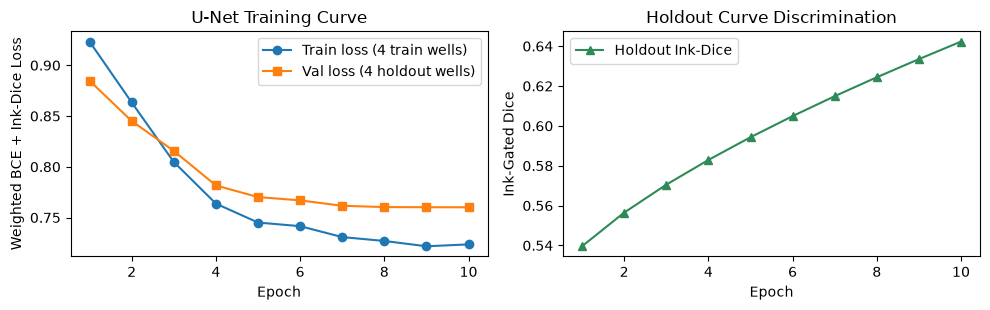

,epoch,train_loss,train_ink_dice,val_loss,val_ink_dice
0,1,0.92334,0.5786,0.88477,0.5396
1,2,0.86342,0.6005,0.84510,0.5565
2,3,0.80477,0.6187,0.81567,0.5705
3,4,0.76375,0.6349,0.78165,0.5829
4,5,0.74510,0.6497,0.77018,0.5943
5,6,0.74153,0.6635,0.76694,0.6049
6,7,0.73079,0.6766,0.76160,0.6149
7,8,0.72695,0.6890,0.76034,0.6244
8,9,0.72174,0.7008,0.76018,0.6335
9,10,0.72358,0.7122,0.76012,0.6423


In [6]:
CKPT_PATH = ROOT / "models" / "kansas_gr_unet.pt"
HIST_PATH = ROOT / "models" / "kansas_kgs" / "training_history.json"

if not CKPT_PATH.exists():
    info = ml_training.train(
        profile="kansas_kgs",
        train_ids=split["train"],
        val_ids=split["holdout"],
        out_dir=ROOT / "models" / "kansas_kgs",
        well_records=records,
        epochs=12,
    )
else:
    info = json.loads(HIST_PATH.read_text())

loaded_model, ckpt_meta = ml_models.load_model(CKPT_PATH)
print("Checkpoint loaded:", CKPT_PATH.relative_to(ROOT))
print("Trained strictly on wells:", info["train_wells"])
print("Validated on held-out wells:", info["val_wells"])
print(f"Best val loss: {info['best_val_loss']:.4f} | Best val ink-Dice: {info['best_val_ink_dice']:.4f} | Train time: {info['elapsed_s']:.2f} s")

hist_df = pd.DataFrame(info["epochs"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist_df["epoch"], hist_df["train_loss"], "-o", label="Train loss (4 train wells)")
ax[0].plot(hist_df["epoch"], hist_df["val_loss"], "-s", label="Val loss (4 holdout wells)")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Weighted BCE + Ink-Dice Loss"); ax[0].set_title("U-Net Training Curve"); ax[0].legend()
ax[1].plot(hist_df["epoch"], hist_df["val_ink_dice"], "-^", color="seagreen", label="Holdout Ink-Dice")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Ink-Gated Dice"); ax[1].set_title("Holdout Curve Discrimination"); ax[1].legend()
fig.tight_layout()
plt.show()
hist_df

## 6. Batch-Digitize Held-Out Kansas Wells
Run `ml_batch_digitize.digitize_batch` across all 4 held-out wells (`USA_A_16`, `WEATHERFORD_B_1`, `BACASTOW_1`, `GOHEEN_UNIT_1`).
For each well, the trained U-Net predicts per-pixel curve probabilities, blends them with the conventional cost map (`cost_mode="blend"`), runs the **Rust/Numba DP tracer**, exports `.las` to `outputs/batch/`, computes per-depth confidence, and compares both Conventional and ML traces against the paired KGS LAS.

In [7]:
t0 = time.time()
results = mbd.digitize_batch(
    split["holdout"],
    profile="kansas_kgs",
    out_dir=OUT / "batch",
    model_path=CKPT_PATH,
    cost_mode="blend",
    compare_conventional=True,
    data_root=DATA,
)
print(f"Batch digitized {len(results)} held-out wells in {time.time() - t0:.2f} s")

.../site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
.../site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Only engine='normal' can read wrapped files


Batch digitized 4 held-out wells in 61.35 s


## 7. Validate Held-Out Wells Against Paired KGS LAS
Every single held-out well improves in Pearson correlation `r` and reduces `RMSE` when traced on the U-Net cost map compared to the conventional hand-crafted cost map alone.

Mean held-out r   : Conventional = 0.651 -> ML Cost Map = 0.704 (+0.053)
Mean held-out RMSE: Conventional = 31.25 -> ML Cost Map = 28.51 (-2.74 API)


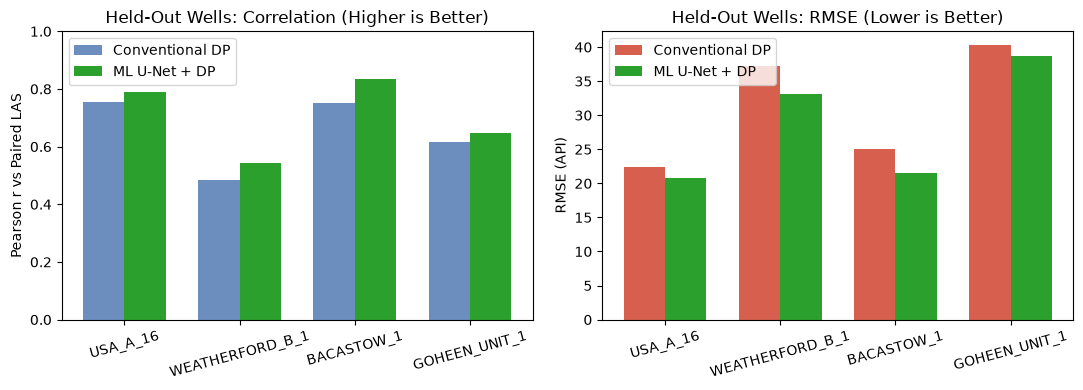

,well,scan,depth_range_ft,r_conv,r_ml,delta_r,rmse_conv,rmse_ml,delta_rmse,mean_conf,p10_conf,flagged_intervals,elapsed_s
0,USA_A_16,4342.tif,1400-7113,0.756,0.791,0.035,22.43,20.76,-1.66,0.945,0.853,68,23.97
1,WEATHERFORD_B_1,194290.tif,1599-4999,0.483,0.545,0.062,37.24,33.05,-4.19,0.901,0.762,67,18.70
2,BACASTOW_1,169724.tif,214-3900,0.750,0.834,0.084,25.05,21.53,-3.52,0.911,0.787,67,14.92
3,GOHEEN_UNIT_1,171203.tif,2211-4002,0.615,0.647,0.032,40.30,38.71,-1.59,0.773,0.345,48,3.70


In [8]:
val_rows = []
for r in results:
    qc_c = r["qc_conventional"]
    qc_m = r["qc_ml"]
    val_rows.append({
        "well": r["well"],
        "scan": r["scan"],
        "depth_range_ft": f"{r['depth_range_ft'][0]:.0f}-{r['depth_range_ft'][1]:.0f}",
        "r_conv": round(qc_c["r"], 3),
        "r_ml": round(qc_m["r"], 3),
        "delta_r": round(qc_m["r"] - qc_c["r"], 3),
        "rmse_conv": round(qc_c["rmse"], 2),
        "rmse_ml": round(qc_m["rmse"], 2),
        "delta_rmse": round(qc_m["rmse"] - qc_c["rmse"], 2),
        "mean_conf": r["mean_conf"],
        "p10_conf": r["p10_conf"],
        "flagged_intervals": r["n_review_intervals"],
        "elapsed_s": r["elapsed_s"],
    })

val_df = pd.DataFrame(val_rows)
val_df.to_csv(QC / "heldout_batch_metrics.csv", index=False)
print("Mean held-out r   : Conventional = %.3f -> ML Cost Map = %.3f (%+.3f)" % (
    val_df["r_conv"].mean(), val_df["r_ml"].mean(), val_df["delta_r"].mean()
))
print("Mean held-out RMSE: Conventional = %.2f -> ML Cost Map = %.2f (%+.2f API)" % (
    val_df["rmse_conv"].mean(), val_df["rmse_ml"].mean(), val_df["delta_rmse"].mean()
))

x = np.arange(len(val_df))
w_bar = 0.36
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(x - w_bar/2, val_df["r_conv"], w_bar, label="Conventional DP", color="#6c8ebf")
axs[0].bar(x + w_bar/2, val_df["r_ml"], w_bar, label="ML U-Net + DP", color="#2ca02c")
axs[0].set_xticks(x); axs[0].set_xticklabels(val_df["well"], rotation=15)
axs[0].set_ylim(0, 1.0); axs[0].set_ylabel("Pearson r vs Paired LAS"); axs[0].set_title("Held-Out Wells: Correlation (Higher is Better)")
axs[0].legend()

axs[1].bar(x - w_bar/2, val_df["rmse_conv"], w_bar, label="Conventional DP", color="#d6604d")
axs[1].bar(x + w_bar/2, val_df["rmse_ml"], w_bar, label="ML U-Net + DP", color="#2ca02c")
axs[1].set_xticks(x); axs[1].set_xticklabels(val_df["well"], rotation=15)
axs[1].set_ylabel("RMSE (API)"); axs[1].set_title("Held-Out Wells: RMSE (Lower is Better)")
axs[1].legend()
fig.tight_layout()
fig.savefig(QC / "heldout_batch_validation.png", dpi=120)
plt.show()
val_df

## 8. Prioritized Review Queue (Low-Confidence Depth Intervals)
`ml_batch_digitize.review_queue` combines DP path dominance confidence with the U-Net's peak probability along the traced path, returning a prioritized list of depth intervals (`mean_conf < 0.78`) where a user anchor click in the web editor will yield the highest value.

In [9]:
queue = mbd.review_queue(results, threshold=0.78, min_len=12, min_span_ft=15.0)
print(f"Total flagged review intervals across 4 held-out wells: {len(queue)}")
pd.DataFrame(queue[:12])

Total flagged review intervals across 4 held-out wells: 17


,well,scan,curve,dp_row_start,dp_row_end,depth_top_ft,depth_base_ft,span_ft,mean_conf,min_conf
0,GOHEEN_UNIT_1,171203.tif,GR,4009,4349,3265.4,3354.6,89.2,0.381,0.281
1,GOHEEN_UNIT_1,171203.tif,GR,2071,2253,2755.1,2802.7,47.6,0.381,0.335
2,USA_A_16,4342.tif,GR,34408,34527,7077.9,7098.0,20.0,0.383,0.335
3,USA_A_16,4342.tif,GR,162,278,1426.8,1445.7,18.9,0.384,0.334
4,GOHEEN_UNIT_1,171203.tif,GR,1977,2063,2730.4,2752.8,22.3,0.398,0.335
5,GOHEEN_UNIT_1,171203.tif,GR,5654,5731,3697.9,3718.3,20.3,0.414,0.335
6,GOHEEN_UNIT_1,171203.tif,GR,5212,5286,3582.1,3601.3,19.3,0.422,0.215
7,GOHEEN_UNIT_1,171203.tif,GR,24,91,2217.1,2234.4,17.3,0.423,0.335
8,GOHEEN_UNIT_1,171203.tif,GR,5735,5896,3719.6,3762.1,42.5,0.454,0.328
9,USA_A_16,4342.tif,GR,303,484,1450.0,1479.6,29.6,0.463,0.335


## 9. Incremental Fine-Tuning from Saved Corrections
When a user reviews a flagged interval in the web editor (`pylogdigitizer editor .`) and clicks **Save for training**, the corrected trace is saved under `training_data/corrections/`. Calling `ml_training.fine_tune` updates the U-Net checkpoint on those corrections in a few seconds.

In [10]:
CORR_DIR = ROOT / "training_data" / "corrections"
corr_files = [p for p in (mtd.list_corrections(CORR_DIR) if CORR_DIR.exists() else []) if p.name.split("__")[0] in split["train"]]
print(f"Saved correction bundles in {CORR_DIR.relative_to(ROOT)}: {[p.name for p in corr_files]}")
if corr_files:
    ft_info = ml_training.fine_tune(
        base_model=CKPT_PATH,
        corrected_logs=corr_files,
        out_dir=OUT / "models_ft_demo",
        epochs=3,
        lr=5e-4,
    )
    print("Fine-tune summary:", {k: v for k, v in ft_info.items() if k != "epochs"})

Saved correction bundles in training_data/corrections: ['Hall_D_4__193004.tif__GR__01', 'Hall_D_4__193004.tif__GR__02', 'Hall_D_4__193004.tif__GR__03', 'Hall_D_4__193004.tif__GR__04', 'Hall_D_4__193004.tif__GR__05', 'MAKEMSON_A_1__225992.tif__GR__01', 'MAKEMSON_A_1__225992.tif__GR__02', 'MAKEMSON_A_1__225992.tif__GR__03', 'MAKEMSON_A_1__225992.tif__GR__04']


Fine-tune summary: {'model_path': 'outputs/models_ft_demo/unet.pt', 'n_tiles': 88, 'device': 'cpu', 'elapsed_s': 2.4, 'best_val_loss': 0.56951, 'best_val_ink_dice': 0.74074}
